# Solutions to notebook 15: Two-dimensional flow: a pseudo-spectral Navier–Stokes solver

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/15_two_dimensional_flow.ipynb)

Worked solutions to the exercises at the end of [notebook 15](../notebooks/15_two_dimensional_flow.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from types import SimpleNamespace
from scipy.fft import rfft2, irfft2

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# functions from notebook 15
def make_grid(N, dealias=True):
    """Grid, wavenumbers and Fourier-space operators for the periodic square with N x N points (N even)."""
    x = 2 * np.pi * np.arange(N) / N
    X, Y = np.meshgrid(x, x, indexing="ij")
    kx = np.fft.fftfreq(N, 1 / N)[:, None]                  # 0, 1, ..., N/2-1, -N/2, ..., -1
    ky = np.fft.rfftfreq(N, 1 / N)[None, :]                 # 0, 1, ..., N/2
    k2 = kx**2 + ky**2
    inv_k2 = np.zeros_like(k2)
    inv_k2[k2 > 0] = 1 / k2[k2 > 0]                         # the mean of ψ is set to zero
    ddx = 1j * kx * (np.abs(kx) < N / 2)                    # first derivatives, Nyquist mode zeroed
    ddy = 1j * ky * (ky < N / 2)
    keep = (np.abs(kx) < N / 3) & (ky < N / 3)              # the 2/3 rule
    mask = keep.astype(float) if dealias else np.ones_like(k2)
    return SimpleNamespace(N=N, X=X, Y=Y, kx=kx, ky=ky, k2=k2, inv_k2=inv_k2, ddx=ddx, ddy=ddy, mask=mask)

def velocity(omega_hat, g, mean_flow=(0.0, 0.0)):
    """Velocity components on the grid from the Fourier coefficients of the vorticity."""
    psi_hat = omega_hat * g.inv_k2
    return mean_flow[0] + irfft2(g.ddy * psi_hat), mean_flow[1] - irfft2(g.ddx * psi_hat)

def rhs(omega_hat, g, mean_flow=(0.0, 0.0)):
    """Fourier coefficients of the advection term −(u ω_x + v ω_y)."""
    u, v = velocity(omega_hat, g, mean_flow)
    return -g.mask * rfft2(u * irfft2(g.ddx * omega_hat) + v * irfft2(g.ddy * omega_hat))

def simulate(omega0, g, nu, dt, n_steps, save_every=None, mean_flow=(0.0, 0.0)):
    """Advance the vorticity field omega0 by n_steps steps of size dt.

    Returns the final vorticity, or the array of fields saved every save_every steps (including the first).
    """
    E = np.exp(-nu * g.k2 * dt / 2)                         # viscous decay over half a step
    E2 = E * E
    w = g.mask * rfft2(omega0)
    saved = [irfft2(w)]
    for n in range(1, n_steps + 1):
        a = rhs(w, g, mean_flow)                            # the four Runge-Kutta stages
        b = rhs(E * (w + dt / 2 * a), g, mean_flow)
        c = rhs(E * w + dt / 2 * b, g, mean_flow)
        d = rhs(E2 * w + dt * E * c, g, mean_flow)
        w = E2 * w + dt / 6 * (E2 * a + 2 * E * (b + c) + d)
        if save_every and n % save_every == 0:
            saved.append(irfft2(w))
    return np.array(saved) if save_every else irfft2(w)

def energy_enstrophy(omega, g):
    """Kinetic energy ½<u² + v²> and enstrophy ½<ω²>, averaged over the box."""
    u, v = velocity(rfft2(omega), g)
    return 0.5 * np.mean(u**2 + v**2), 0.5 * np.mean(omega**2)

def double_shear_layer(g, delta=0.15):
    wrap = lambda d: (d + np.pi) % (2 * np.pi) - np.pi                    # periodic distance in y
    sheet = lambda y0: 1 / (delta * np.cosh(wrap(g.Y - y0) / delta) ** 2)
    return sheet(3 * np.pi / 2) - sheet(np.pi / 2) + 0.1 * np.cos(2 * g.X) + 0.02 * np.cos(g.X + 1)

In [3]:
# a helper for these solutions: a row of vorticity (or other field) snapshots on the periodic square
def show_row(axes, fields, titles, limit, cmap="RdBu_r", vmin=None):
    for ax, field, title in zip(axes, fields, titles):
        image = ax.imshow(field.T, origin="lower", extent=(0, 2 * np.pi, 0, 2 * np.pi), cmap=cmap,
                          vmin=-limit if vmin is None else vmin, vmax=limit)
        ax.set(title=title, xticks=[0, np.pi, 2 * np.pi], yticks=[0, np.pi, 2 * np.pi],
               xticklabels=["0", "π", "2π"], yticklabels=["0", "π", "2π"])
        ax.grid(False)
    return image

## Exercise 1

**A diffusing vortex.** In an unbounded fluid the Gaussian (Lamb–Oseen) vortex
$\omega = \dfrac{a_0^2}{a^2}\exp(-r^2/a^2)$ with $a^2 = a_0^2 + 4\nu t$ is an exact solution,
where $r$ is the distance from its centre. Start the solver from this field with
$a_0 = 0.3$, centred at $(\pi, \pi)$, with $\nu = 0.01$, $N = 64$ and $\Delta t = 0.01$, and
compare with the formula at $t = 2$. The mean vorticity of this field is not zero, although
15.1 says that it must be on a periodic domain. What does the solver do with the mean, and
which flow does it therefore compute? How large is the error, and where does it come from?

Run the solver and subtract the formula. To find out where the error comes from, change one
thing at a time: the time step, the grid, and the advection term (switching it off leaves pure
diffusion, which in Fourier space is the multiplication by $e^{-\nu k^2 t}$). An error that
survives all three changes is not a numerical error. It belongs to the problem.

mean vorticity: 0.00716197 at t = 0, 0.00716197 at t = 2, a0²/4π = 0.00716197
largest error at t = 2:  N = 64, dt = 0.01: 8.32e-06   (peak vorticity 0.529)
                         N = 64, dt = 0.005: 8.32e-06     N = 96, dt = 0.01: 8.43e-06
diffusion alone (no advection), N = 64: 3.4e-10


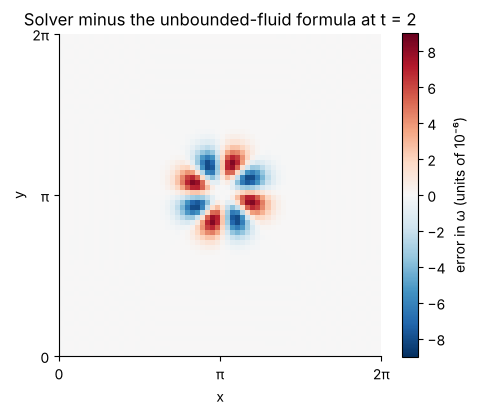

In [4]:
a0, nu, T = 0.3, 0.01, 2.0

def lamb_oseen(g, t):
    a2 = a0**2 + 4 * nu * t
    return a0**2 / a2 * np.exp(-((g.X - np.pi) ** 2 + (g.Y - np.pi) ** 2) / a2)

def vortex_error(N, dt):
    g = make_grid(N)
    return simulate(lamb_oseen(g, 0.0), g, nu, dt, round(T / dt)) - lamb_oseen(g, T), g

error, g = vortex_error(64, 0.01)
error_half_step = np.abs(vortex_error(64, 0.005)[0]).max()
error_finer_grid = np.abs(vortex_error(96, 0.01)[0]).max()
diffusion_only = irfft2(np.exp(-nu * g.k2 * T) * g.mask * rfft2(lamb_oseen(g, 0.0)))
error_diffusion = np.abs(diffusion_only - lamb_oseen(g, T)).max()
mean_start, mean_end = lamb_oseen(g, 0.0).mean(), (error + lamb_oseen(g, T)).mean()

print(f"mean vorticity: {mean_start:.8f} at t = 0, {mean_end:.8f} at t = 2, a0²/4π = {a0**2 / (4 * np.pi):.8f}")
print(f"largest error at t = 2:  N = 64, dt = 0.01: {np.abs(error).max():.2e}   (peak vorticity {lamb_oseen(g, T).max():.3f})")
print(f"                         N = 64, dt = 0.005: {error_half_step:.2e}     N = 96, dt = 0.01: {error_finer_grid:.2e}")
print(f"diffusion alone (no advection), N = 64: {error_diffusion:.1e}")

fig, ax = plt.subplots(figsize=(5.2, 4.2))
image = show_row([ax], [1e6 * error], ["Solver minus the unbounded-fluid formula at t = 2"], 9)
ax.set(xlabel="x", ylabel="y")
fig.colorbar(image, ax=ax, label="error in ω (units of 10⁻⁶)");

In [5]:
# verify: the mean against the integral of the Gaussian, and the error against changes of dt, N and the advection term
assert abs(mean_start - a0**2 / (4 * np.pi)) < 1e-12 and abs(mean_end - mean_start) < 1e-15
assert 5e-6 < np.abs(error).max() < 1.2e-5
assert abs(error_half_step / np.abs(error).max() - 1) < 1e-3          # not a time-stepping error
assert abs(error_finer_grid / np.abs(error).max() - 1) < 0.05         # not a resolution error
assert error_diffusion < 1e-8                                         # diffusion alone agrees with the formula
quarter_turn = error[-np.arange(g.N) % g.N, :].T                      # the error field turned by 90° about (π, π)
assert np.abs(error - quarter_turn).max() < 1e-12                     # the four-fold symmetry of the square array

**Answer.** The mean vorticity is $a_0^2/4\pi = 0.00716$, and the solver leaves it exactly
where it is: the coefficient with $k = 0$ is not damped ($k^2 = 0$), receives nothing from the
advection term, and is ignored when the velocity is computed, because `inv_k2` is zero there.
The flow that is computed is therefore that of $\omega$ minus its mean: a square array of
vortices, one per box, in a uniform background of weak opposite vorticity that makes the total
circulation zero. The error against the formula for a single vortex in an unbounded fluid is
$8.3\times10^{-6}$, about $1.6\times10^{-5}$ of the peak. It does not change when the time step
is halved or the grid refined, and diffusion alone reproduces the formula to $3\times10^{-10}$,
so it is not a numerical error. It is the effect of the neighbouring vortices and of the
background, whose velocity field is not circular: it strains the vortex slightly, with the
four-fold pattern of the square array that the plot shows. A periodic box is a model of an
unbounded fluid only as long as the structures in it are small compared with the box.

## Exercise 2

**Growth rate of the Kelvin–Helmholtz instability.** Start from the two vorticity sheets of
15.7 ($\delta = 0.15$, $\nu = 10^{-3}$, $N = 128$, $\Delta t = 0.02$) with the single
disturbance $10^{-4}\cos 2x$ in place of the two used there. Save the field every 5 steps up
to $t = 6$ and record the amplitude of the Fourier coefficient of the vertical velocity $v$
with $(k_x, k_y) = (2, 0)$. Fit the exponential growth rate over $3 \le t \le 5$. (Before
$t \approx 3$ the disturbance is still settling into the growing mode, and afterwards the rate
keeps drifting because the layer thickens by diffusion, so the fit is an average.) Repeat for
disturbances $\cos x$, $\cos 3x$ and $\cos 4x$ (same amplitude, reading the coefficient
with the matching $k_x$). Which two grow fastest? For an inviscid layer of constant thickness
$\delta$, linear theory (Michalke, 1964) gives the fastest growth at $k\delta \approx 0.44$
with rate $0.19/\delta$. Compare, and explain the direction of the difference.

While the disturbance is small it grows like $e^{\sigma t}$, so $\log|\hat v|$ is nearly a
straight line in time and $\sigma$ is its slope. The coefficient with $k_y = 0$ is the average
of $v$ over $y$, which is where the two layers together leave their mark. The mean of the
vorticity over $x$ gives the thickness of the layer while this happens: for the profile of
15.7 the peak of the mean vorticity is $1/\delta$. The local slope is printed as well, to show
how far the growth is from a clean exponential.

disturbance   k δ     growth rate σ    σ δ     local slope within the fit interval
  cos 1x     0.15        0.778     0.117       0.74 to 0.79
  cos 2x     0.30        0.939     0.141       0.91 to 1.02
  cos 3x     0.45        0.990     0.148       0.79 to 1.21
  cos 4x     0.60        0.510     0.077      -0.22 to 1.24
inviscid theory for a layer of thickness 0.15: fastest at k δ = 0.44, σ = 0.19/δ = 1.267
measured layer thickness: 0.150 at t = 0, 0.183 at t = 3, 0.193 at t = 4, 0.201 at t = 5
theory with the thickness at t = 4: σ = 0.987, fastest wavenumber 2.28


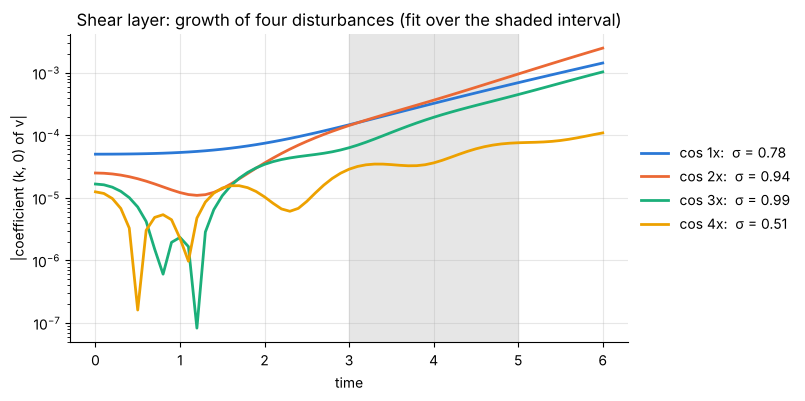

In [6]:
delta, nu_layer = 0.15, 1e-3
times = 0.1 * np.arange(61)
fit = (times >= 3) & (times <= 5)

def growth(m, N=128, dt=0.02):
    """Amplitude history of the (m, 0) coefficient of v, its fitted growth rate and the layer thickness history."""
    g = make_grid(N)
    start = double_shear_layer(g, delta) - 0.1 * np.cos(2 * g.X) - 0.02 * np.cos(g.X + 1) + 1e-4 * np.cos(m * g.X)
    fields = simulate(start, g, nu_layer, dt, round(6 / dt), save_every=round(0.1 / dt))
    amplitude = np.array([abs(rfft2(velocity(rfft2(field), g)[1])[m, 0]) / N**2 for field in fields])
    thickness = 1 / np.abs(fields.mean(axis=1)).max(axis=1)
    return amplitude, np.polyfit(times[fit], np.log(amplitude[fit]), 1)[0], thickness

results = {m: growth(m) for m in (1, 2, 3, 4)}
print("disturbance   k δ     growth rate σ    σ δ     local slope within the fit interval")
for m, (amplitude, sigma, thickness) in results.items():
    local = np.gradient(np.log(amplitude), times)[fit]
    print(f"  cos {m}x     {m * delta:.2f}    {sigma:9.3f}     {sigma * delta:.3f}      {local.min():5.2f} to {local.max():.2f}")
sigma_2, sigma_3, thickness_2 = results[2][1], results[3][1], results[2][2]
print(f"inviscid theory for a layer of thickness 0.15: fastest at k δ = 0.44, σ = 0.19/δ = {0.19 / delta:.3f}")
print(f"measured layer thickness: {thickness_2[0]:.3f} at t = 0, {thickness_2[30]:.3f} at t = 3, {thickness_2[40]:.3f} at t = 4, {thickness_2[50]:.3f} at t = 5")
print(f"theory with the thickness at t = 4: σ = {0.19 / thickness_2[40]:.3f}, fastest wavenumber {0.44 / thickness_2[40]:.2f}")

fig, ax = plt.subplots(figsize=(7.2, 4))
for m, (amplitude, sigma, thickness) in results.items():
    ax.semilogy(times, amplitude, label=f"cos {m}x:  σ = {sigma:.2f}")
ax.axvspan(3, 5, color="0.9", zorder=0)
ax.set(xlabel="time", ylabel="|coefficient (k, 0) of v|", title="Shear layer: growth of four disturbances (fit over the shaded interval)")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [7]:
# verify: the rate must not depend on the discretization, and must agree with the published theory at the measured thickness
check_2, check_3 = growth(2, N=96, dt=0.01)[1], growth(3, N=96, dt=0.01)[1]
print(f"with N = 96 and dt = 0.01: σ = {check_2:.4f} for cos 2x and {check_3:.4f} for cos 3x   (N = 128, dt = 0.02: {sigma_2:.4f} and {sigma_3:.4f})")
assert abs(check_2 / sigma_2 - 1) < 2e-3 and abs(check_3 / sigma_3 - 1) < 1e-2
assert sorted(results, key=lambda m: results[m][1])[-2:] in ([2, 3], [3, 2])       # the two fastest, well ahead of the others
assert min(sigma_2, sigma_3) > 1.15 * max(results[1][1], results[4][1])
assert abs(thickness_2[0] - delta) < 1e-3
theory = 0.19 / thickness_2[40]                                                    # Michalke's rate at the thickness in mid-interval
assert abs(sigma_2 / theory - 1) < 0.1 and abs(sigma_3 / theory - 1) < 0.1
assert 2 < 0.44 / thickness_2[40] < 3 and max(sigma_2, sigma_3) < 0.19 / delta

with N = 96 and dt = 0.01: σ = 0.9396 for cos 2x and 0.9946 for cos 3x   (N = 128, dt = 0.02: 0.9393 and 0.9897)


**Answer.** The disturbances $\cos 3x$ and $\cos 2x$ grow fastest and almost equally fast,
with $\sigma = 0.99$ and $0.94$, well ahead of $\cos x$ (0.78) and $\cos 4x$ (0.51). The
theory for a layer of constant thickness 0.15 predicts the fastest growth at
$k = 0.44/\delta = 2.9$ with $\sigma = 1.27$: the measured rates are lower and the preferred
wave is longer. Both differences come from viscosity, and mostly through one effect: the layer
diffuses while the wave grows. Its thickness has risen from 0.150 to 0.193 at the middle of
the fitting interval, and the theory with that thickness gives $\sigma = 0.19/0.193 = 0.99$,
fastest at $k = 2.3$, between the two waves that the computation prefers. (Direct viscous
damping of the wave, of order $\nu k^2 = 0.004$ to $0.009$, is negligible.) The fitted rates
are averages, as the exercise warns: within the interval the local slope runs from 0.91 to
1.02 for $\cos 2x$ and from 0.79 to 1.21 for $\cos 3x$, so the order of these two is not
significant, and for $\cos 4x$ the slope is too irregular for the fit to mean much. For the
engineer: a shear layer selects a wavelength of about fourteen times its current thickness,
so a thicker layer rolls up into larger and slower billows.

## Exercise 3

**Kolmogorov flow.** Add a steady body force to the vorticity equation by adding the term
$F(x, y) = -n^3\nu\cos(ny)$ with $n = 4$ to the right-hand side (in `rhs`, as the Fourier
transform of $F$). Show by hand that $\omega = -n\cos(ny)$, the flow $u = \sin(ny)$, is a
steady solution. Start from that solution plus the disturbance $0.01\cos(x + 0.3)$ and run
to $t = 100$ with $N = 64$, $\Delta t = 0.04$, for $\nu = 0.5$ and for $\nu = 0.05$. In which
case does the flow return to the steady solution? Plot the final vorticity for both.

**By hand.** For $\omega = -n\cos(ny)$ the Poisson equation $\nabla^2\psi = -\omega$ gives
$\psi = -\cos(ny)/n$, so $u = \psi_y = \sin(ny)$ and $v = 0$. The advection term
$u\,\omega_x + v\,\omega_y$ vanishes because $\omega_x = 0$ and $v = 0$. The viscous term is
$\nu\nabla^2\omega = \nu n^3\cos(ny)$, which the force $F = -n^3\nu\cos(ny)$ cancels exactly:
$\omega_t = 0$. The force keeps the flow going against viscosity.

In the code the force is a constant array added to every evaluation of `rhs`, so the
time-stepping loop is that of `simulate` with one more term.

ν = 0.5: largest distance from the steady solution at t = 100: 1.45e-05     energy 0.2500 (steady solution: 0.25)
          power put in by the force 4.000015, dissipated by viscosity 4.000029


ν = 0.05: largest distance from the steady solution at t = 100: 4.01e+00     energy 0.1932 (steady solution: 0.25)
          power put in by the force 0.098324, dissipated by viscosity 0.098322


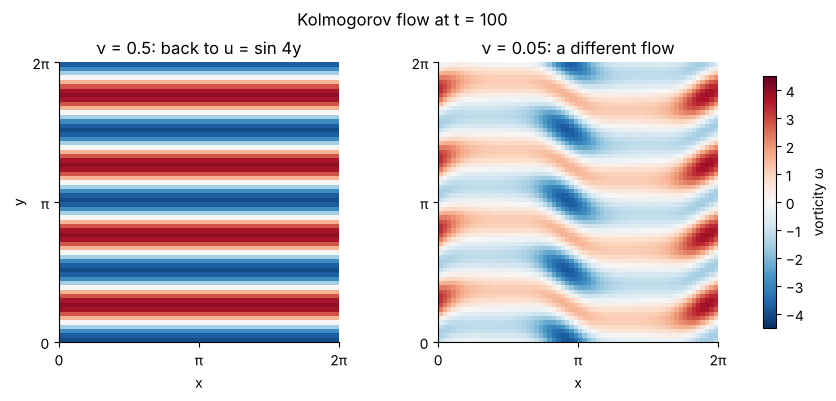

In [8]:
def simulate_forced(omega0, g, nu, dt, n_steps, force_hat):
    """As simulate, with the Fourier coefficients force_hat of a steady body force added to the advection term."""
    f = lambda w: rhs(w, g) + force_hat
    E = np.exp(-nu * g.k2 * dt / 2)
    E2 = E * E
    w = g.mask * rfft2(omega0)
    for n in range(n_steps):
        a = f(w)
        b = f(E * (w + dt / 2 * a))
        c = f(E * w + dt / 2 * b)
        d = f(E2 * w + dt * E * c)
        w = E2 * w + dt / 6 * (E2 * a + 2 * E * (b + c) + d)
    return irfft2(w)

n_force, dt = 4, 0.04
g = make_grid(64)
steady = -n_force * np.cos(n_force * g.Y)
final, residual, budget = {}, {}, {}
for nu in (0.5, 0.05):
    force_hat = rfft2(-n_force**3 * nu * np.cos(n_force * g.Y))
    residual[nu] = np.abs(rhs(rfft2(steady), g) + force_hat - nu * g.k2 * rfft2(steady)).max() / g.N**2
    final[nu] = simulate_forced(steady + 0.01 * np.cos(g.X + 0.3), g, nu, dt, round(100 / dt), force_hat)
    psi = irfft2(rfft2(final[nu]) * g.inv_k2)
    budget[nu] = (np.mean(psi * irfft2(force_hat)), 2 * nu * energy_enstrophy(final[nu], g)[1])
    print(f"ν = {nu}: largest distance from the steady solution at t = 100: {np.abs(final[nu] - steady).max():.2e}"
          f"     energy {energy_enstrophy(final[nu], g)[0]:.4f} (steady solution: 0.25)")
    print(f"          power put in by the force {budget[nu][0]:.6f}, dissipated by viscosity {budget[nu][1]:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.9), constrained_layout=True)
image = show_row(axes, [final[0.5], final[0.05]], ["ν = 0.5: back to u = sin 4y", "ν = 0.05: a different flow"], 4.5)
axes[0].set(xlabel="x", ylabel="y")
axes[1].set(xlabel="x")
fig.colorbar(image, ax=axes, label="vorticity ω", shrink=0.9)
fig.suptitle("Kolmogorov flow at t = 100");

In [9]:
# verify: the hand solution makes the right-hand side vanish, and the final states satisfy the energy budget
assert max(residual.values()) < 1e-11                                   # ω = −n cos(ny) is steady for both viscosities
assert np.abs(final[0.5] - steady).max() < 1e-4                         # ν = 0.5 returns (to the time-stepping error)
assert np.abs(final[0.05] - steady).max() > 1.0                         # ν = 0.05 does not
for nu in (0.5, 0.05):
    assert abs(budget[nu][0] / budget[nu][1] - 1) < 1e-4                # dE/dt = <ψF> − 2νZ = 0 in a steady state
assert abs(budget[0.5][1] - 4.0) < 1e-3                                 # 2νZ = ν n²/2 = 4 for the steady solution

**Answer.** With $\nu = 0.5$ the disturbance dies out and the flow returns to
$\omega = -4\cos 4y$, to within $1.5\times10^{-5}$, which is the time-stepping error of
treating the force explicitly. With $\nu = 0.05$ it does not: the disturbance grows, the
straight bands buckle, and the flow settles into a different pattern with a large-scale
meander, 4.0 away from the steady solution and with a kinetic energy of 0.193 where the
parallel flow has 0.25. In both final states the power supplied by the force equals the viscous
dissipation, as it must once the flow has stopped changing. The parameter that decides is the
Reynolds number $Re = 1/(n\nu)$, here 0.5 and 5: the linear theory of this flow (Meshalkin and
Sinai, 1961) puts the loss of stability at $Re = \sqrt2$ for very long disturbances. A steady
solution found by hand says nothing about whether the flow will be observed. Stability has to
be checked separately.

## Exercise 4

**Mixing a passive scalar.** A dye of concentration $c$ obeys
$c_t + u\,c_x + v\,c_y = \kappa\nabla^2 c$. Extend the solver to advance $c$ together with
$\omega$, with the same integrating-factor method. Use the shear layer of 15.7 at $N = 128$
and $\Delta t = 0.016$, with $\kappa = 10^{-3}$ and $c(x, y, 0) = \cos y$. Compute the variance
$\langle c^2\rangle$ up to $t = 14.4$ and compare it with pure diffusion, for which
$\langle c^2\rangle = \tfrac12 e^{-2\kappa t}$. By what factor has the roll-up increased the
loss of variance?

The scalar equation has the same form as the vorticity equation, with $\kappa$ in place of
$\nu$ and with a velocity that it does not influence. So carry a second array through the
Runge–Kutta stages, with its own integrating factor $e^{-\kappa k^2 t}$ and the same
dealiased advection term. Multiplying the equation by $c$ and averaging over the box gives the
variance budget $\tfrac{d}{dt}\langle c^2\rangle = -2\kappa\langle|\nabla c|^2\rangle$, in which
advection does not appear: stirring destroys no variance by itself. It steepens the gradients,
and diffusion does the rest. The budget is the check.

variance at t = 14.4: 0.3274 with the flow, 0.4858 by diffusion alone
variance lost: 0.1726 against 0.0142, a factor of 12.2
range of the computed concentration over the run: -1.028 to 1.037


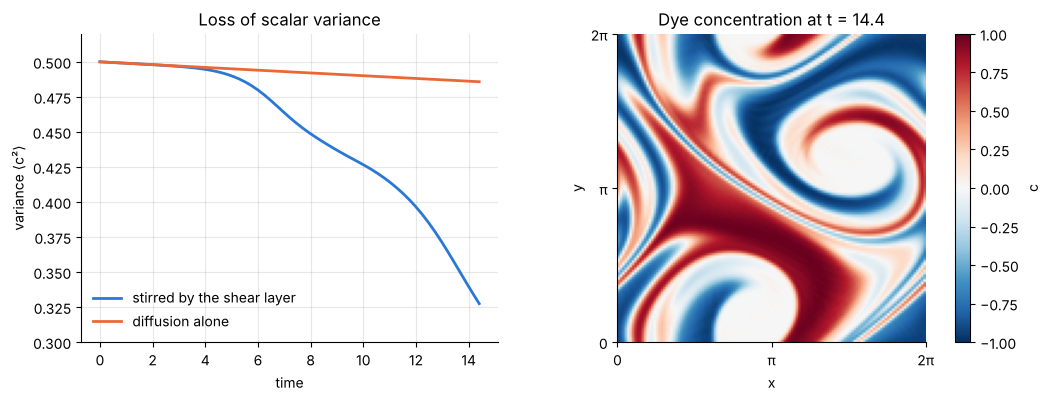

In [10]:
def simulate_with_scalar(omega0, c0, g, nu, kappa, dt, n_steps, save_every):
    """Advance vorticity and a passive scalar together; returns the scalar fields saved every save_every steps."""
    def f(w, c):
        u, v = velocity(w, g)
        advect = lambda q: -g.mask * rfft2(u * irfft2(g.ddx * q) + v * irfft2(g.ddy * q))
        return advect(w), advect(c)
    E, G = np.exp(-nu * g.k2 * dt / 2), np.exp(-kappa * g.k2 * dt / 2)
    E2, G2 = E * E, G * G
    w, c = g.mask * rfft2(omega0), g.mask * rfft2(c0)
    saved = [irfft2(c)]
    for n in range(1, n_steps + 1):
        a1, b1 = f(w, c)
        a2, b2 = f(E * (w + dt / 2 * a1), G * (c + dt / 2 * b1))
        a3, b3 = f(E * w + dt / 2 * a2, G * c + dt / 2 * b2)
        a4, b4 = f(E2 * w + dt * E * a3, G2 * c + dt * G * b3)
        w = E2 * w + dt / 6 * (E2 * a1 + 2 * E * (a2 + a3) + a4)
        c = G2 * c + dt / 6 * (G2 * b1 + 2 * G * (b2 + b3) + b4)
        if n % save_every == 0:
            saved.append(irfft2(c))
    return np.array(saved)

kappa, dt, every = 1e-3, 0.016, 15
g = make_grid(128)
dye = simulate_with_scalar(double_shear_layer(g), np.cos(g.Y), g, 1e-3, kappa, dt, 900, every)
dye_times = dt * every * np.arange(len(dye))
variance = (dye**2).mean(axis=(1, 2))
diffusion = 0.5 * np.exp(-2 * kappa * dye_times)
factor = (0.5 - variance[-1]) / (0.5 - diffusion[-1])
print(f"variance at t = {dye_times[-1]:.1f}: {variance[-1]:.4f} with the flow, {diffusion[-1]:.4f} by diffusion alone")
print(f"variance lost: {0.5 - variance[-1]:.4f} against {0.5 - diffusion[-1]:.4f}, a factor of {factor:.1f}")
print(f"range of the computed concentration over the run: {dye.min():.3f} to {dye.max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.9), constrained_layout=True)
axes[0].plot(dye_times, variance, label="stirred by the shear layer")
axes[0].plot(dye_times, diffusion, label="diffusion alone")
axes[0].set(xlabel="time", ylabel="variance ⟨c²⟩", ylim=(0.3, 0.52), title="Loss of scalar variance")
axes[0].legend(frameon=False, loc="lower left")
image = show_row([axes[1]], [dye[-1]], [f"Dye concentration at t = {dye_times[-1]:.1f}"], 1.0)
axes[1].set(xlabel="x", ylabel="y")
fig.colorbar(image, ax=axes[1], label="c");

In [11]:
# verify: pure diffusion when there is no flow, and the variance budget when there is
at_rest = simulate_with_scalar(np.zeros_like(g.X), np.cos(g.Y), g, 1e-3, kappa, dt, 30, 30)[-1]
assert abs((at_rest**2).mean() - 0.5 * np.exp(-2 * kappa * 30 * dt)) < 1e-13
gradient_squared = np.array([np.mean(irfft2(g.ddx * rfft2(c)) ** 2 + irfft2(g.ddy * rfft2(c)) ** 2) for c in dye])
budget = 2 * kappa * np.trapezoid(gradient_squared, dye_times)
print(f"variance lost {variance[0] - variance[-1]:.5f}   2κ ∫ <|∇c|²> dt = {budget:.5f}")
assert abs(budget / (variance[0] - variance[-1]) - 1) < 1e-3              # limited by the trapezoidal rule in time
assert np.all(np.diff(variance) < 0) and abs(dye[-1].mean()) < 1e-12      # variance only falls, the amount of dye is conserved
assert 10 < factor < 14

variance lost 0.17256   2κ ∫ <|∇c|²> dt = 0.17253


**Answer.** At $t = 14.4$ the variance has fallen from 0.5 to 0.327, while diffusion alone
would have left 0.486: the roll-up has increased the loss of variance by a factor of 12. The
billows wind the dye into thin sheets, the gradients across the sheets grow, and diffusion,
which works on gradients, becomes that much more effective. This is how stirring mixes, and
why a mixing layer is used to bring fuel and air together. The dealiased advection term
conserves the mean of $c$ to rounding. It does not keep $c$ between $-1$ and 1: the thinnest
sheets are at the limit of this grid and the computed field overshoots by a few per cent.

## Exercise 5

**Do two vortices merge?** Place two Gaussian vortices $10\exp(-r^2/a^2)$ with $a = 0.3$ at
$(\pi \pm b/2, \pi)$ and run with $\nu = 10^{-3}$, $N = 128$, $\Delta t = 0.02$ up to
$t = 20$, once with separation $b = 0.8$ and once with $b = 2$. Plot the vorticity at
$t = 0, 5, 10, 15, 20$ for each case. In which case do the two vortices merge into one?
Make the answer quantitative with the ratio of the vorticity at the midpoint $(\pi, \pi)$
to the largest vorticity in the field, as a function of time.

Two runs of the unchanged solver. Two vortices of the same sign orbit their common centre. If
they are far apart they behave like point vortices of circulation $\Gamma = 10\pi a^2$, which
at a separation $b$ orbit with angular velocity $\Gamma/(\pi b^2)$ and keep their distance.
If they are close, each is strained by the other until they exchange vorticity and merge. At
the midpoint the vorticity is low between two separate vortices and is the maximum of a merged
one, so the ratio asked for measures the merger.

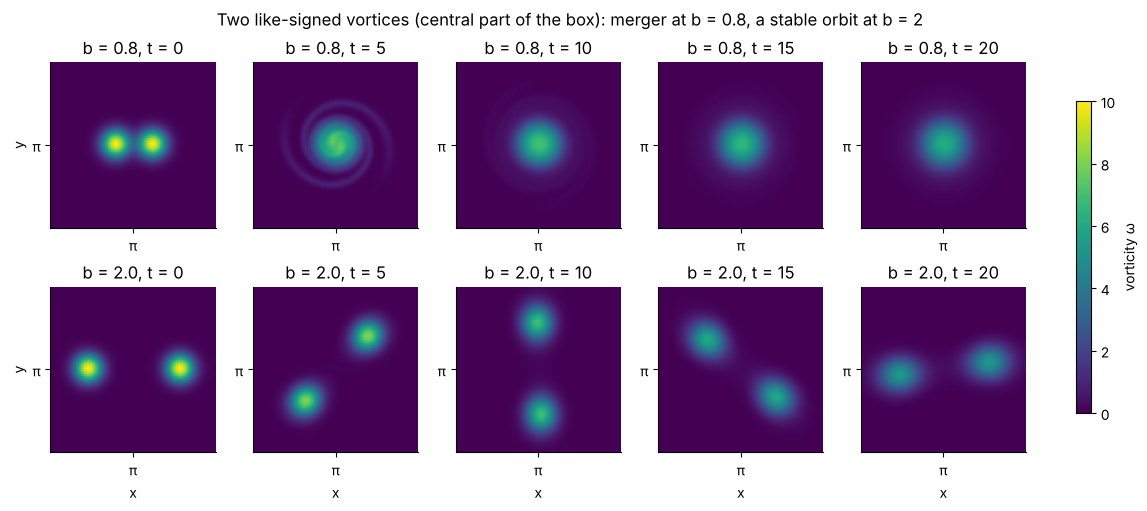

In [12]:
a, nu_pair, dt, every = 0.3, 1e-3, 0.02, 25
g = make_grid(128)
blob = lambda x0: 10 * np.exp(-((g.X - x0) ** 2 + (g.Y - np.pi) ** 2) / a**2)
pair_times = dt * every * np.arange(41)
pairs = {b: simulate(blob(np.pi - b / 2) + blob(np.pi + b / 2), g, nu_pair, dt, 1000, save_every=every) for b in (0.8, 2.0)}
ratio = {b: fields[:, g.N // 2, g.N // 2] / fields.max(axis=(1, 2)) for b, fields in pairs.items()}   # the point (π, π) is index N/2

fig, axes = plt.subplots(2, 5, figsize=(11.5, 5.0), constrained_layout=True)
for row, (b, fields) in zip(axes, pairs.items()):
    image = show_row(row, fields[::10], [f"b = {b}, t = {t:.0f}" for t in pair_times[::10]], 10, cmap="viridis", vmin=0)
    row[0].set_ylabel("y")
for ax in axes.ravel():
    ax.set(xlim=(np.pi - 1.8, np.pi + 1.8), ylim=(np.pi - 1.8, np.pi + 1.8), xticks=[np.pi], xticklabels=["π"], yticks=[np.pi], yticklabels=["π"])
for ax in axes[1]:
    ax.set_xlabel("x")
fig.colorbar(image, ax=axes, label="vorticity ω", shrink=0.8)
fig.suptitle("Two like-signed vortices (central part of the box): merger at b = 0.8, a stable orbit at b = 2");

b = 0.8: midpoint / peak vorticity = 0.338 at t = 0, 0.945 at t = 5, 1.000 at t = 10, 1.000 at t = 20   (largest during the run 1.000)
b = 2.0: midpoint / peak vorticity = 0.000 at t = 0, 0.010 at t = 5, 0.017 at t = 10, 0.061 at t = 20   (largest during the run 0.061)
b = 0.8: the ratio first exceeds 0.99 at t = 6.5


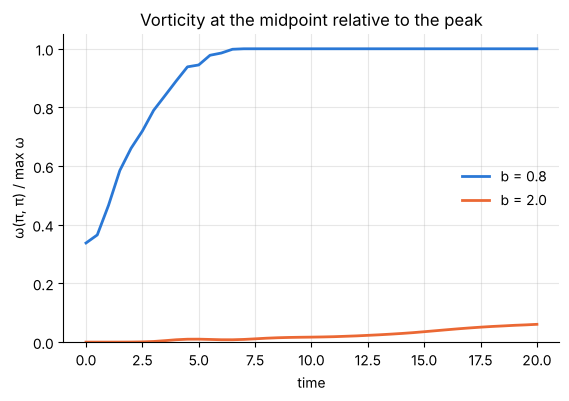

In [13]:
fig, ax = plt.subplots()
for b in pairs:
    ax.plot(pair_times, ratio[b], label=f"b = {b}")
ax.set(xlabel="time", ylabel="ω(π, π) / max ω", ylim=(0, 1.05), title="Vorticity at the midpoint relative to the peak")
ax.legend(frameon=False, loc="center right")
for b in pairs:
    print(f"b = {b}: midpoint / peak vorticity = {ratio[b][0]:.3f} at t = 0, {ratio[b][10]:.3f} at t = 5, {ratio[b][20]:.3f} at t = 10,"
          f" {ratio[b][-1]:.3f} at t = 20   (largest during the run {ratio[b].max():.3f})")
print(f"b = 0.8: the ratio first exceeds 0.99 at t = {pair_times[np.argmax(ratio[0.8] > 0.99)]:.1f}")

The check on the pair that survives is its rate of rotation, with one correction that
exercise 1 explains. The solver computes the two vortices in a uniform background of vorticity
$-2\Gamma/(2\pi)^2$, and a uniform vorticity turns the fluid like a rigid body at half that
rate. The expected angular velocity is therefore $\Gamma/(\pi b^2) - \Gamma/(4\pi^2)$. The
orientation of the pair follows from the second moments of the vorticity about the centre.

In [14]:
# verify: the energy budget dE/dt = −2νZ and constant circulation for both runs; the orbit of the pair that survives
circulation = 10 * np.pi * a**2
for b, fields in pairs.items():
    E, Z = np.array([energy_enstrophy(field - field.mean(), g) for field in fields]).T    # the mean vorticity drives no flow
    assert abs(2 * nu_pair * np.trapezoid(Z, pair_times) / (E[0] - E[-1]) - 1) < 1e-3
    assert np.abs(fields.mean(axis=(1, 2)) - 2 * circulation / (2 * np.pi) ** 2).max() < 1e-12
dx, dy = g.X - np.pi, g.Y - np.pi
moments = [np.array([(field * q).sum() for field in pairs[2.0]]) for q in (dx * dy, dx**2 - dy**2)]
angle = 0.5 * np.unwrap(np.arctan2(2 * moments[0], moments[1]))               # orientation of the pair
orbit_rate = np.polyfit(pair_times, angle, 1)[0]
unbounded, periodic = circulation / (np.pi * 2.0**2), circulation / (np.pi * 2.0**2) - circulation / (4 * np.pi**2)
print(f"b = 2: the pair turns at {orbit_rate:.3f} rad per time unit; point vortices: {unbounded:.3f} unbounded, {periodic:.3f} with the periodic background")
assert abs(orbit_rate / periodic - 1) < 0.1 and abs(orbit_rate / unbounded - 1) > 0.2
assert ratio[0.8][-1] > 0.999 and ratio[0.8][0] < 0.4 and ratio[2.0].max() < 0.1
assert min(fields.min() for fields in pairs.values()) > -0.02 * 10             # resolved: no ripples beyond 2 per cent of the peak

b = 2: the pair turns at 0.164 rad per time unit; point vortices: 0.225 unbounded, 0.153 with the periodic background


**Answer.** The pair with $b = 0.8$ merges and the pair with $b = 2$ does not. For
$b = 0.8$ the midpoint vorticity rises from 0.34 of the peak to 0.95 at $t = 5$, and from
$t = 7$ on the midpoint is the peak: a single vortex, surrounded for a while by the spiral
arms that the merger throws off. For $b = 2$ the ratio stays below 0.07 and the two vortices
orbit each other for the whole run, at 0.164 rad per time unit. That is 7 per cent above the
point-vortex estimate for the periodic box, 0.153, and far from the unbounded value 0.225, so
the background of exercise 1 is not a small effect here. The two runs bracket the critical
separation between 2.7 and 6.7 initial core radii $a$. Viscosity makes the cores grow, so a
pair that starts far enough apart to survive comes closer to merging as time passes: the slow
rise of the lower curve shows it. In decaying two-dimensional turbulence (15.8) the merger is
the event that turns many small vortices into a few large ones.